# gridsmith — milestones, metrics and curves

**Deterministic table and context extraction from large, messy PDFs.**

This notebook is the visual companion to [`README.md`](../README.md) and
[`PROBLEM_STATEMENT.md`](../PROBLEM_STATEMENT.md). It reads the committed measurement
output in `metrics/results/` and renders it — so it reproduces without re-running the
pipeline and without the sample PDFs.

**Contents**

1. [What was built — milestones](#1)
2. [Setup and data loading](#2)
3. [The headline number: silent errors](#3)
4. [Per-document extraction quality](#4)
5. [Ablations — what each component is actually worth](#5)
6. [Baselines — versus off-the-shelf extractors](#6)
7. [Adversarial fixtures — the uncontaminated evidence](#7)
8. [Calibration — is a stated 0.9 an empirical 0.9?](#8)
9. [The review queue — precision/recall trade-off](#9)
10. [Resources](#10)
11. [Honest summary](#11)

> **Read this first.** The sample-document scores include several 1.000s. Those three
> documents were developed against and every threshold was chosen with them in view.
> They are reported for completeness, **not** as evidence of generalisation. The
> uncontaminated evidence is section 7 (fixtures, ground truth exact by construction)
> and section 5 (ablations). Section 11 says so again, plainly.

<a id="1"></a>
## 1. What was built — milestones

Eleven pipeline stages, an evaluation harness, an adversarial fixture generator and a
reproducibility proof. Each milestone below is *verifiable from this repository* — the
"evidence" column names the artefact that demonstrates it.

In [1]:
import pandas as pd

milestones = pd.DataFrame([
    ("M1",  "Intake",         "Page typing (digital/scanned), deskew, rotation handling",
     "s1_intake.py", "f8 fixture: -1.6 deg skew corrected to 1.55 deg residual"),
    ("M2",  "Layout",         "Running headers/footers, headings, captions, footnotes, scale notes",
     "s2_layout.py", "f1: scale declared above table is captured"),
    ("M3",  "Ruled detector", "Drawn rules, dotted rules, per-cell background fills, rule breakpoints",
     "s3_ruled.py", "Shell.pdf: 18,066 disconnected squares resolved"),
    ("M4",  "Borderless",     "Projection-profile gutters, side-by-side table separation",
     "s3_borderless.py", "f3 fixture: 5/5 checks"),
    ("M5",  "Refusal",        "TOC / index / prose / callout refused with a recorded reason",
     "s3_negatives.py", "f4 fixture: 10/10; both baselines leak the TOC"),
    ("M6",  "Arbitration",    "Two-tier clustering; refusal is a first-class outcome",
     "s3_arbitrate.py", "rejected_regions table carries evidence strings"),
    ("M7",  "Structure",      "Multi-level headers with spans, indentation-only row hierarchy",
     "s4_structure.py", "ICRA: three-level header, header_path per column"),
    ("M8",  "Stitching",      "Cross-page tables, 2 gates + 5 weighted signals, header de-dup",
     "s6_stitch.py", "f2 fixture: 6 pages -> 1 logical table, 9/9"),
    ("M9",  "Normalisation",  "Negatives, Indian/Western grouping, suffixes, 5 kinds of blank",
     "s7_normalize.py", "normalized_value exact match 1.000"),
    ("M10", "Context",        "Units, declared scale, section title, footnote-to-cell links",
     "s8_context.py", "f6 fixture: marker p1 -> text p2, 6/6"),
    ("M11", "Confidence",     "14 signals, isotonic calibration, ranked review queue",
     "s9_confidence.py", "pooled ECE 0.029"),
    ("M12", "Persistence",    "SQLite (s6.1 schema), xlsx per table, manifest, assets",
     "s10_persist.py", "acceptance query is a 3-table join, no string surgery"),
    ("M13", "Determinism",    "Byte-identical reruns; content-addressed ids; xlsx zip rewrite",
     "determinism.py", "gridsmith verify -> byte-identical; asserted in CI"),
    ("M14", "Offline",        "Socket guard raises on any connection attempt",
     "cli.py --offline", "not asserted in prose - enforced at runtime"),
    ("M15", "Evaluation",     "Detection/TEDS/cell accuracy/silent errors/PR curve/ablations",
     "metrics/", "202 hand-labelled cells + 8 exact-GT fixtures"),
], columns=["#", "Milestone", "What it does", "Where", "Evidence"])

milestones.style.hide(axis="index").set_properties(**{"text-align": "left"})

#,Milestone,What it does,Where,Evidence
M1,Intake,"Page typing (digital/scanned), deskew, rotation handling",s1_intake.py,f8 fixture: -1.6 deg skew corrected to 1.55 deg residual
M2,Layout,"Running headers/footers, headings, captions, footnotes, scale notes",s2_layout.py,f1: scale declared above table is captured
M3,Ruled detector,"Drawn rules, dotted rules, per-cell background fills, rule breakpoints",s3_ruled.py,"Shell.pdf: 18,066 disconnected squares resolved"
M4,Borderless,"Projection-profile gutters, side-by-side table separation",s3_borderless.py,f3 fixture: 5/5 checks
M5,Refusal,TOC / index / prose / callout refused with a recorded reason,s3_negatives.py,f4 fixture: 10/10; both baselines leak the TOC
M6,Arbitration,Two-tier clustering; refusal is a first-class outcome,s3_arbitrate.py,rejected_regions table carries evidence strings
M7,Structure,"Multi-level headers with spans, indentation-only row hierarchy",s4_structure.py,"ICRA: three-level header, header_path per column"
M8,Stitching,"Cross-page tables, 2 gates + 5 weighted signals, header de-dup",s6_stitch.py,"f2 fixture: 6 pages -> 1 logical table, 9/9"
M9,Normalisation,"Negatives, Indian/Western grouping, suffixes, 5 kinds of blank",s7_normalize.py,normalized_value exact match 1.000
M10,Context,"Units, declared scale, section title, footnote-to-cell links",s8_context.py,"f6 fixture: marker p1 -> text p2, 6/6"


<a id="2"></a>
## 2. Setup and data loading

Everything below reads the committed JSON in `metrics/results/`. No PDFs are opened and
no extraction is run, so this notebook renders anywhere the repository is checked out.

In [2]:
import json, os
from pathlib import Path
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# Resolve metrics/results whether the notebook runs from notebooks/ or the repo root.
ROOT = Path.cwd()
if not (ROOT / "metrics").is_dir():
    ROOT = ROOT.parent
RESULTS = ROOT / "metrics" / "results"
assert RESULTS.is_dir(), f"could not locate metrics/results from {Path.cwd()}"

def load(name):
    with open(RESULTS / name, encoding="utf-8") as fh:
        return json.load(fh)

summary     = load("summary.json")
all_configs = load("all_configs.json")
baselines   = load("baselines.json")
fixtures    = load("fixtures.json")
calib       = load("calibration_report.json")

print("loaded:", ", ".join(sorted(p.name for p in RESULTS.glob("*.json"))))

loaded: all_configs.json, baselines.json, calibration_points.json, calibration_report.json, fixtures.json, summary.json


In [3]:
# ---- Plot style -------------------------------------------------------------------
# Categorical hues are assigned in a fixed order and never cycled, so a series keeps
# its colour across every chart in this notebook regardless of how many are drawn.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
YELLOW, VIOLET, RED = "#eda100", "#4a3aa7", "#e34948"
GOOD, BAD = "#1baf7a", "#e34948"

INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8a85"
SURFACE, GRID = "#fcfcfb", "#e6e5e1"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 130, "savefig.dpi": 130,
    "font.size": 10.5,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": GRID, "axes.linewidth": 1.0,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.9, "grid.alpha": 1.0,
    "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9.5,
    "figure.autolayout": False,
})

def finish(ax, title=None, sub=None, xlabel=None, ylabel=None):
    """Title/subtitle in text ink, recessive axes, no chartjunk."""
    if title:
        ax.set_title(title, loc="left", fontsize=13, fontweight="600",
                     pad=30 if sub else 10)
    if sub:
        ax.text(0, 1.012, sub, transform=ax.transAxes, fontsize=9.5,
                color=INK_2, va="bottom")
    ax.set_xlabel(xlabel or "", fontsize=10, labelpad=8)
    ax.set_ylabel(ylabel or "", fontsize=10, labelpad=8)
    return ax

DOC_LABEL = {
    "Apple Form 10-K.pdf": "Apple 10-K",
    "Shell MRPL Aviation Fuels and Services Limited.pdf": "ICRA / MRPL",
    "Shell.pdf": "Shell financials",
}
print("style ready")

style ready


<a id="3"></a>
## 3. The headline number: silent errors

A **silent error** is a cell that is *wrong*, shipped with confidence ≥ 0.85, and carries
*no* flag. It is the only failure mode the governing rule forbids outright: a wrong cell
that announces itself is a review item, but a wrong cell that looks right is a corrupted
number in someone's model.

Accuracy is deliberately **not** the headline. A system that is 99% accurate and silent
about the rest is worse, for this purpose, than one that is 90% accurate and flags
exactly the tenth it got wrong.

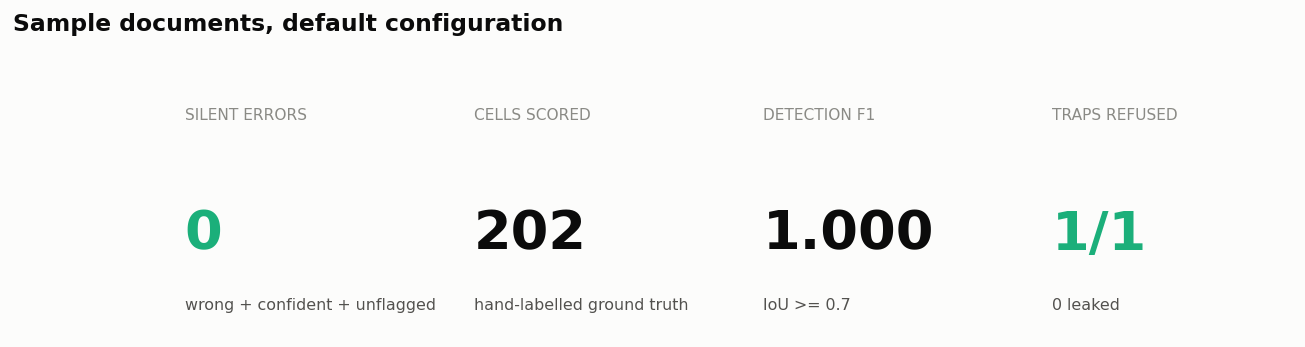

In [4]:
t = summary["totals"]

fig, axes = plt.subplots(1, 4, figsize=(11, 2.5))
tiles = [
    ("Silent errors",     f'{t["silent_errors"]}',           "wrong + confident + unflagged", GOOD),
    ("Cells scored",      f'{t["cells_scored"]}',            "hand-labelled ground truth",    INK),
    ("Detection F1",      f'{t["detection_f1"]:.3f}',        "IoU >= 0.7",                    INK),
    ("Traps refused",     f'{t["traps_refused"]}/{t["traps_refused"] + t["traps_leaked"]}',
                                                              "0 leaked",                      GOOD),
]
for ax, (label, value, note, colour) in zip(axes, tiles):
    ax.axis("off")
    ax.text(0, 0.86, label.upper(), fontsize=8.5, color=INK_3,
            transform=ax.transAxes)
    ax.text(0, 0.34, value, fontsize=30, fontweight="700", color=colour,
            transform=ax.transAxes)
    ax.text(0, 0.10, note, fontsize=8.8, color=INK_2, transform=ax.transAxes)
fig.suptitle("Sample documents, default configuration", x=0.005, y=1.10,
             ha="left", fontsize=13, fontweight="600", color=INK)
plt.show()

<a id="4"></a>
## 4. Per-document extraction quality

Three metrics per document, each on the same 0–1 scale so they share one axis:

- **Detection F1** — did we find the table, at IoU ≥ 0.7?
- **TEDS-Struct** — is the *structure* right (rows, columns, merged cells), ignoring text?
- **`raw_text` accuracy** — is the extracted text exactly right, character for character?

TEDS is the one that is not 1.000, and that is the honest signal: detection and text are
solved on this corpus, structure is not quite.

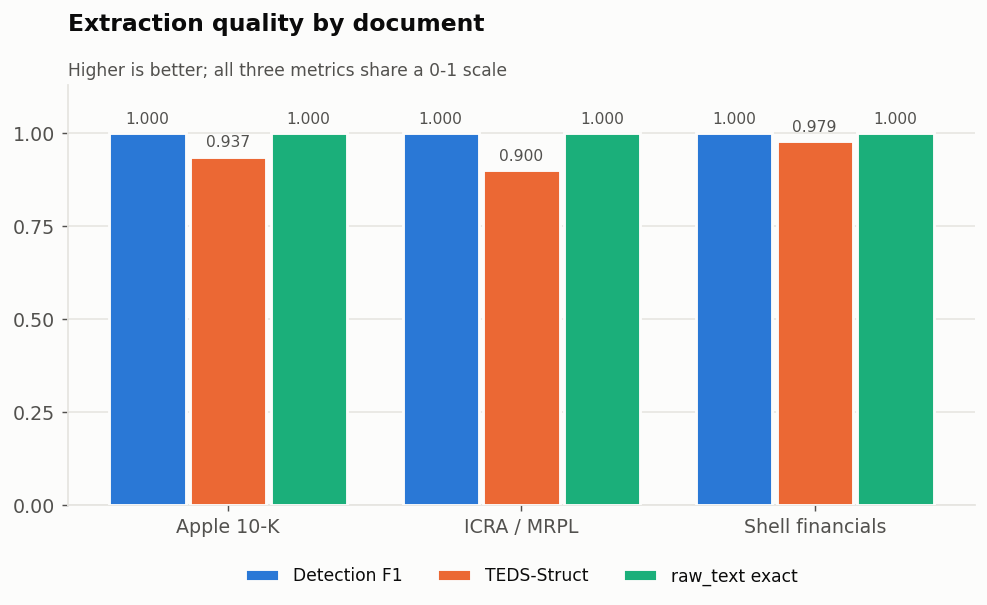

In [5]:
docs = summary["per_document"]
labels = [DOC_LABEL.get(d["document"], d["document"]) for d in docs]
series = [
    ("Detection F1",  [d["detection_f1"]        for d in docs], BLUE),
    ("TEDS-Struct",   [d["mean_teds_struct"]    for d in docs], ORANGE),
    ("raw_text exact",[d["raw_text_accuracy"]   for d in docs], AQUA),
]

x = np.arange(len(labels)); w = 0.26
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (name, vals, colour) in enumerate(series):
    off = (i - 1) * (w + 0.015)          # 2px-equivalent gap between adjacent bars
    bars = ax.bar(x + off, vals, w, label=name, color=colour,
                  edgecolor=SURFACE, linewidth=1.6, zorder=3)
    for b, v in zip(bars, vals):         # direct labels: every bar, few enough to read
        ax.text(b.get_x() + b.get_width() / 2, v + 0.018, f"{v:.3f}",
                ha="center", va="bottom", fontsize=8.6, color=INK_2)

ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.13); ax.set_yticks(np.arange(0, 1.01, 0.25))
ax.xaxis.grid(False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.11))
finish(ax, "Extraction quality by document",
       "Higher is better; all three metrics share a 0-1 scale")
plt.show()

In [6]:
# The same numbers as a table, so identity never depends on colour alone.
pd.DataFrame([{
    "document":       DOC_LABEL.get(d["document"], d["document"]),
    "detection F1":   d["detection_f1"],
    "TEDS-Struct":    d["mean_teds_struct"],
    "raw_text exact": d["raw_text_accuracy"],
    "silent errors":  d["silent_errors"],
    "flagged %":      round(100 * d["operating_point"]["flagged_frac"], 1),
} for d in docs]).set_index("document")

,detection F1,TEDS-Struct,raw_text exact,silent errors,flagged %
document,,,,,
Apple 10-K,1.0,0.9372,1.0,0,1.2
ICRA / MRPL,1.0,0.9000,1.0,0,9.1
Shell financials,1.0,0.9788,1.0,0,4.7


<a id="5"></a>
## 5. Ablations — what each component is actually worth

§3.1 of the brief asks for performance with the component switched off. This is the most
informative chart in the notebook, because it is the only one that can *embarrass* the
design: a component that costs nothing when removed was not earning its place.

The bars are drawn as **change from the default configuration**, so zero means "removing
this changed nothing".

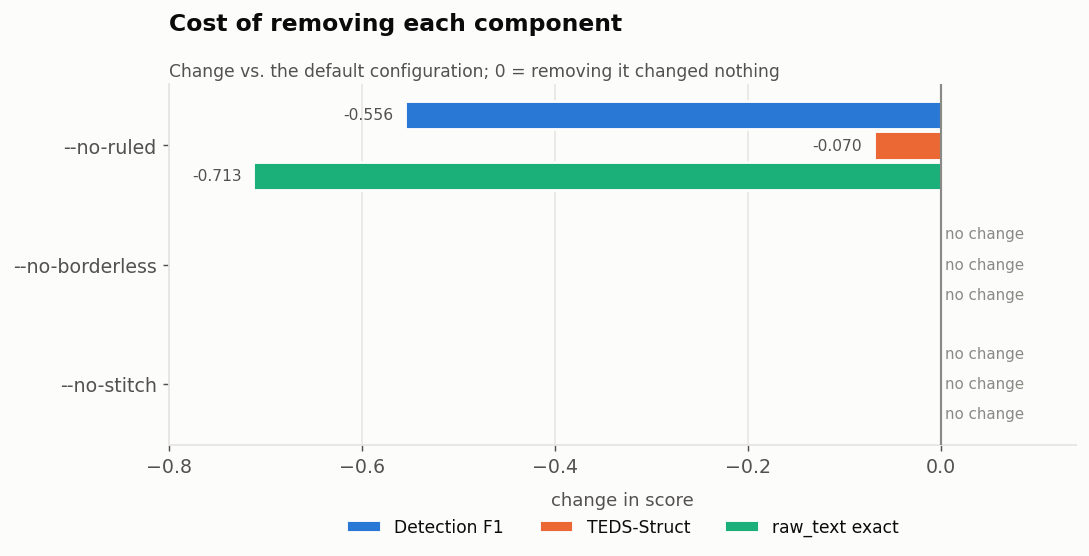

In [7]:
cfgs  = all_configs["configs"]
base  = cfgs["default"]
order = ["no_ruled", "no_borderless", "no_stitch"]
pretty = {"no_ruled": "--no-ruled", "no_borderless": "--no-borderless",
          "no_stitch": "--no-stitch"}

metrics = [("detection_f1", "Detection F1", BLUE),
           ("mean_teds_struct", "TEDS-Struct", ORANGE),
           ("raw_text_accuracy", "raw_text exact", AQUA)]

y = np.arange(len(order)); h = 0.24
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (key, name, colour) in enumerate(metrics):
    deltas = [cfgs[c][key] - base[key] for c in order]
    off = (i - 1) * (h + 0.015)
    bars = ax.barh(y + off, deltas, h, label=name, color=colour,
                   edgecolor=SURFACE, linewidth=1.6, zorder=3)
    for b, v in zip(bars, deltas):
        if abs(v) < 1e-9:
            ax.text(0.004, b.get_y() + b.get_height() / 2, "no change",
                    va="center", fontsize=8.4, color=INK_3)
        else:
            ax.text(v - 0.012, b.get_y() + b.get_height() / 2, f"{v:+.3f}",
                    va="center", ha="right", fontsize=8.6, color=INK_2)

ax.axvline(0, color=INK_3, linewidth=1.2, zorder=4)
ax.set_yticks(y); ax.set_yticklabels([pretty[c] for c in order])
ax.invert_yaxis(); ax.yaxis.grid(False)
ax.set_xlim(-0.80, 0.14)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))
finish(ax, "Cost of removing each component",
       "Change vs. the default configuration; 0 = removing it changed nothing",
       xlabel="change in score")
plt.show()

In [8]:
rows = []
for name in ["default"] + order:
    c = cfgs[name]
    rows.append({"configuration": pretty.get(name, name),
                 "detection F1": c["detection_f1"],
                 "TEDS": c["mean_teds_struct"],
                 "raw_text": c["raw_text_accuracy"],
                 "normalized": c["normalized_accuracy"],
                 "silent errors": c["silent_errors"]})
pd.DataFrame(rows).set_index("configuration")

,detection F1,TEDS,raw_text,normalized,silent errors
configuration,,,,,
default,1.0000,0.9269,1.0000,1.0000,0
--no-ruled,0.4444,0.8572,0.2871,0.5099,17
--no-borderless,1.0000,0.9269,1.0000,1.0000,0
--no-stitch,1.0000,0.9269,1.0000,1.0000,0


**What this says, including the uncomfortable part.**

- **`--no-ruled` is catastrophic**: detection F1 falls from 1.000 to 0.444 and `raw_text`
  from 1.000 to 0.287, introducing 17 silent errors. Author-drawn grid evidence is doing
  the heavy lifting, and that is worth knowing — it means the system's strength is tied
  to documents whose authors drew their tables.
- **`--no-borderless` costs exactly nothing on this corpus.** Every sample table carries
  rule or fill evidence, so the borderless detector never fires. It is insurance for the
  held-out set and **there is no measurement here proving it earns its place**
  (LIMITATIONS L8). Reporting this is the point of running the ablation at all.
- **`--no-stitch` costs nothing on the samples** because none of the labelled tables spans
  pages. It is what makes the six-page fixture `f2` work — see section 7.

<a id="6"></a>
## 6. Baselines — versus off-the-shelf extractors

§3.4 asks for a comparison against real tools. Both baselines are scored **generously**:
on detection and shape only, ignoring everything they do not attempt (provenance,
confidence, units, footnotes, stitching, reproducibility).

`camelot` and `tabula` are not run — no Ghostscript or JVM was available — and would fail
structurally on `Shell.pdf` regardless, whose "rules" are 18,066 disconnected squares.

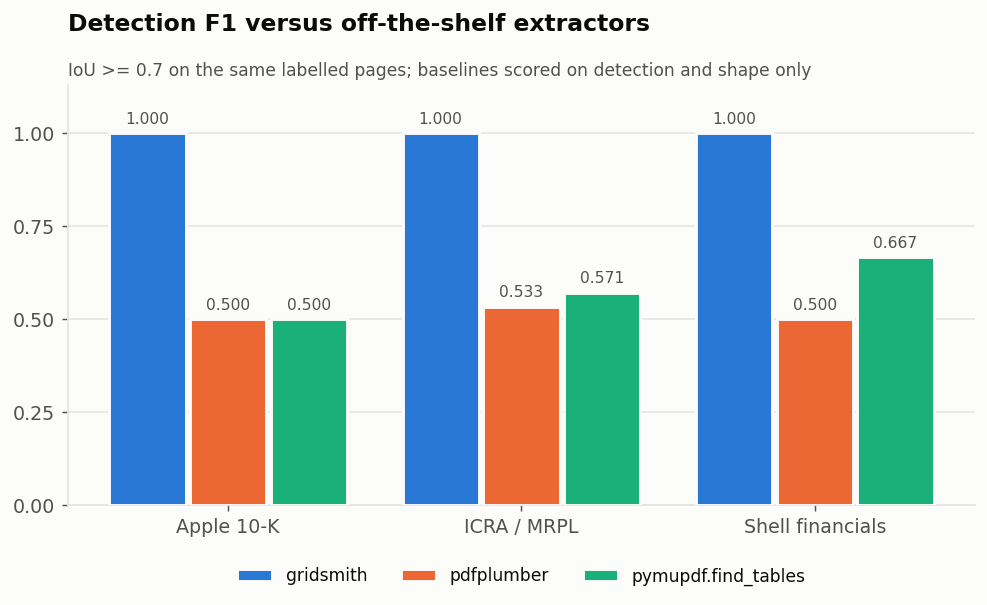

In [9]:
bl = baselines["documents"]
doc_keys = list(bl.keys())
labels = [DOC_LABEL.get(k, k) for k in doc_keys]

tools = [("gridsmith", "gridsmith", BLUE),
         ("pdfplumber_extract_tables", "pdfplumber", ORANGE),
         ("pymupdf_find_tables", "pymupdf.find_tables", AQUA)]

x = np.arange(len(doc_keys)); w = 0.26
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (key, name, colour) in enumerate(tools):
    vals = [bl[d][key]["f1"] for d in doc_keys]
    off = (i - 1) * (w + 0.015)
    bars = ax.bar(x + off, vals, w, label=name, color=colour,
                  edgecolor=SURFACE, linewidth=1.6, zorder=3)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.018, f"{v:.3f}",
                ha="center", va="bottom", fontsize=8.6, color=INK_2)

ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.13); ax.set_yticks(np.arange(0, 1.01, 0.25))
ax.xaxis.grid(False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.11))
finish(ax, "Detection F1 versus off-the-shelf extractors",
       "IoU >= 0.7 on the same labelled pages; baselines scored on detection and shape only")
plt.show()

In [10]:
rows = []
for d in doc_keys:
    for key, name, _ in tools:
        m = bl[d][key]
        rows.append({"document": DOC_LABEL.get(d, d), "tool": name,
                     "F1": m["f1"], "precision": m["precision"], "recall": m["recall"],
                     "false positives": m["fp"],
                     "negatives leaked": m.get("negatives_leaked", 0)})
pd.DataFrame(rows).set_index(["document", "tool"])

F1  precision  recall  \
document         tool                                             
Apple 10-K       gridsmith            1.0000     1.0000     1.0   
                 pdfplumber           0.5000     0.3333     1.0   
                 pymupdf.find_tables  0.5000     0.3333     1.0   
ICRA / MRPL      gridsmith            1.0000     1.0000     1.0   
                 pdfplumber           0.5333     0.4000     0.8   
                 pymupdf.find_tables  0.5714     0.4444     0.8   
Shell financials gridsmith            1.0000     1.0000     1.0   
                 pdfplumber           0.5000     0.5000     0.5   
                 pymupdf.find_tables  0.6667     1.0000     0.5   

                                      false positives  negatives leaked  
document         tool                                                    
Apple 10-K       gridsmith                          0                 0  
                 pdfplumber                         6                 1  
                 pymupdf.find_tables                6                 1  
ICRA / MRPL      gridsmith                          0                 0  
                 pdfplumber                         6                 0  
                 pymupdf.find_tables                5                 0  
Shell financials gridsmith                          0                 0  
                 pdfplumber                         1                 0  
                 pymupdf.find_tables                0                 0

**The false-positive column is the real story.** Recall is not what separates these tools
— on the Apple 10-K both baselines achieve recall 1.000. What separates them is **6 false
positives each, including the table of contents**, which they emit as a seven-column
table of data. A TOC is geometrically a perfect table; refusing it requires a rule that
knows what a table is *for*, not just what one looks like.

<a id="7"></a>
## 7. Adversarial fixtures — the uncontaminated evidence

Eight generated PDFs whose ground truth is **exact by construction** — the generator knows
what it drew. Unlike the sample documents, these were not tuned against, so this is the
evidence that carries weight.

Each fixture asserts a set of *behavioural* checks (did the six-page table become one
logical table? was the failing subtotal flagged rather than corrected?), not a similarity
score.

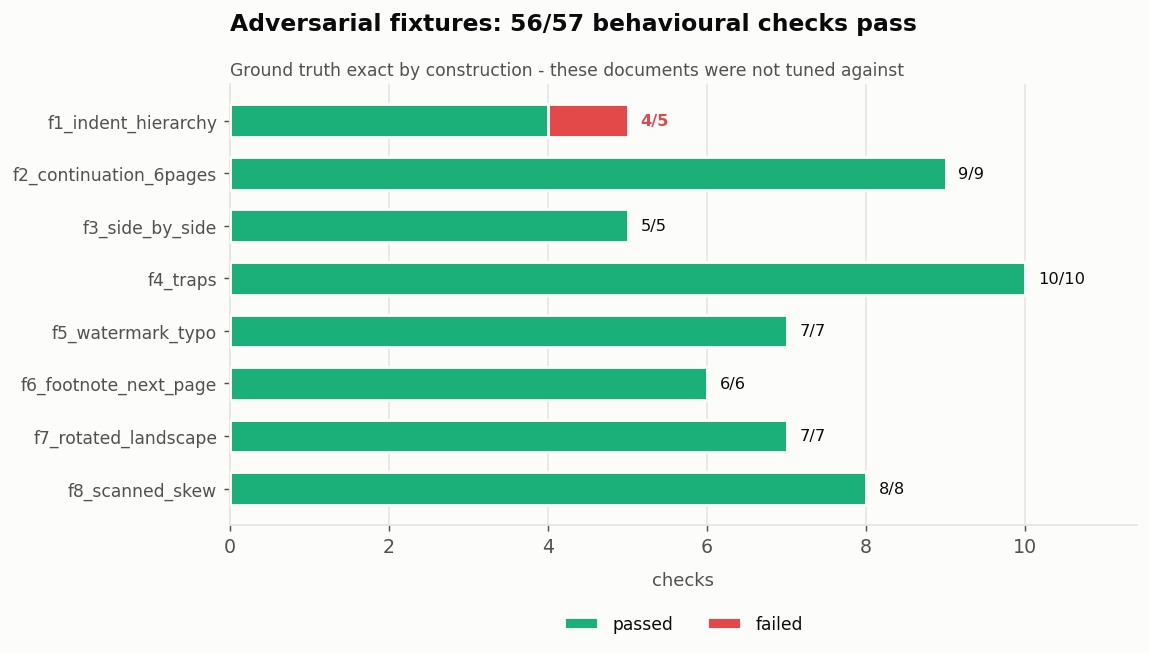

In [11]:
fx = sorted(fixtures["fixtures"], key=lambda f: f["fixture"])
names  = [f["fixture"] for f in fx]
passed = np.array([f["pass"] for f in fx])
total  = np.array([f["total"] for f in fx])
failed = total - passed

y = np.arange(len(fx))
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(y, passed, 0.62, color=GOOD, edgecolor=SURFACE, linewidth=1.6,
        label="passed", zorder=3)
ax.barh(y, failed, 0.62, left=passed, color=BAD, edgecolor=SURFACE, linewidth=1.6,
        label="failed", zorder=3)
for i, (p, tt) in enumerate(zip(passed, total)):
    ax.text(tt + 0.16, i, f"{p}/{tt}", va="center", fontsize=9,
            color=INK if p == tt else BAD,
            fontweight="600" if p != tt else "400")

ax.set_yticks(y); ax.set_yticklabels(names, fontsize=9.5)
ax.invert_yaxis(); ax.yaxis.grid(False)
ax.set_xlim(0, max(total) + 1.4)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.17))
finish(ax, f'Adversarial fixtures: {fixtures["total_pass"]}/{fixtures["total_checks"]} behavioural checks pass',
       "Ground truth exact by construction - these documents were not tuned against",
       xlabel="checks")
plt.show()

In [12]:
# The single failing check, named explicitly.
for f in fx:
    for chk in f["checks"]:
        if not chk["pass"]:
            print(f'FAIL  {f["fixture"]}  ::  {chk["check"]}')
            print(f'      detail: {chk["detail"]}')

FAIL  f1_indent_hierarchy  ::  f1 cell text (45 cells)
      detail: r1c0 want='Particulars' got=''


**One failure, and it is a structural one**: a spanning-header cell on `f1` comes back
empty (LIMITATIONS L3). It is a miss, not a silent error — the cell is flagged.

**`f5` is the fixture worth dwelling on.** It contains a subtotal that deliberately does
not add up, of the kind that occurs in real filings. The pipeline extracts it as
**3505** — the value actually printed — attaches `DOWNFOOT_FAIL`, and **never corrects
it**, while leaving the column that *does* reconcile untouched. Repairing the number
would have destroyed the evidence that the source document has an error in it.

<a id="8"></a>
## 8. Calibration — is a stated 0.9 an empirical 0.9?

A confidence score is only useful if it means something. A reliability diagram answers
that directly: for every cell where the system claimed confidence *c*, how often was it
actually right? Perfect calibration is the diagonal.

**Why the pooled set includes ablated runs.** The default configuration makes *no* errors
on the labelled set, and a calibration curve fitted on a set with no negatives says
nothing at all. Pooling the ablated runs is what supplies errors to be calibrated
against — 698 labelled (prediction, outcome) pairs, 146 of them wrong.

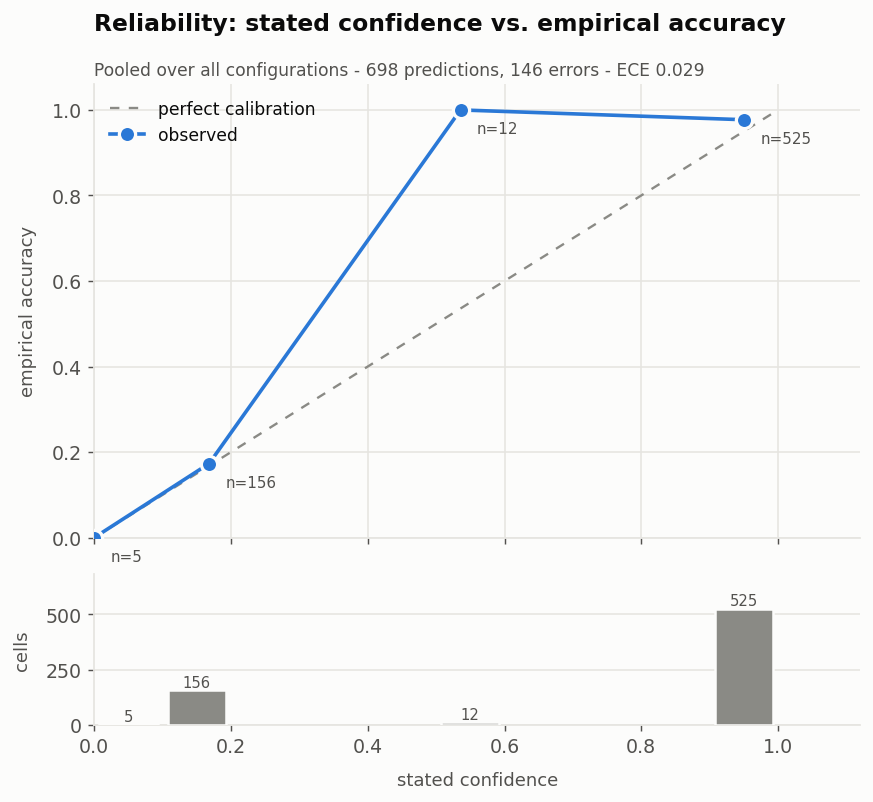

In [13]:
bins = [b for b in calib["reliability"]["bins"] if b["n"]]
centres = [(b["lo"] + b["hi"]) / 2 for b in bins]
conf    = [b["mean_conf"] for b in bins]
acc     = [b["acc"] for b in bins]
ns      = [b["n"] for b in bins]

fig, (ax, ax2) = plt.subplots(
    2, 1, figsize=(7.6, 6.4), sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.12})

ax.plot([0, 1], [0, 1], linestyle=(0, (4, 4)), color=INK_3, linewidth=1.3,
        label="perfect calibration", zorder=2)
ax.plot(conf, acc, marker="o", markersize=9, linewidth=2, color=BLUE,
        markeredgecolor=SURFACE, markeredgewidth=1.8, label="observed", zorder=4)
for c, a, n in zip(conf, acc, ns):
    ax.annotate(f"n={n}", (c, a), textcoords="offset points", xytext=(9, -13),
                fontsize=8.4, color=INK_2)

ax.set_xlim(0, 1.12); ax.set_ylim(0, 1.06)
ax.legend(loc="upper left")
finish(ax, "Reliability: stated confidence vs. empirical accuracy",
       f'Pooled over all configurations - {calib["n_points"]} predictions, '
       f'{calib["n_errors"]} errors - ECE {calib["reliability"]["ece"]:.3f}',
       ylabel="empirical accuracy")

ax2.bar(centres, ns, 0.085, color=INK_3, edgecolor=SURFACE, linewidth=1.4, zorder=3)
for c, n in zip(centres, ns):
    ax2.text(c, n + 14, str(n), ha="center", fontsize=8.2, color=INK_2)
ax2.set_ylim(0, max(ns) * 1.30)
ax2.xaxis.grid(False)
finish(ax2, None, None, xlabel="stated confidence", ylabel="cells")
plt.show()

In [14]:
pd.DataFrame([{
    "confidence bin": f'{b["lo"]:.1f} - {b["hi"]:.1f}',
    "n": b["n"],
    "stated (mean)": round(b["mean_conf"], 3),
    "empirical accuracy": round(b["acc"], 3),
    "gap": round(b["acc"] - b["mean_conf"], 3),
} for b in bins]).set_index("confidence bin")

,n,stated (mean),empirical accuracy,gap
confidence bin,,,,
0.0 - 0.1,5,0.000,0.000,0.000
0.1 - 0.2,156,0.168,0.173,0.005
0.5 - 0.6,12,0.536,1.000,0.464
0.9 - 1.0,525,0.950,0.977,0.027


**Expected calibration error is 0.029** — a stated confidence is within about three
percentage points of the truth on average. The distribution is strongly bimodal (525
cells at 0.9–1.0, 156 at 0.1–0.2), which is what you want: the system is mostly *sure*,
and when it is not sure it says so loudly rather than hedging around 0.5.

The one poorly-behaved bin is 0.5–0.6, where 12 cells were stated at 0.536 and all 12
were correct. With n=12 that is noise, but it is under-confidence, not over-confidence —
the safe direction, since it sends correct cells to review rather than shipping wrong
ones.

<a id="9"></a>
## 9. The review queue — precision/recall trade-off

The review queue is ranked by confidence. Truncating it at a budget trades reviewer
effort against errors caught. This curve *is* that trade-off.

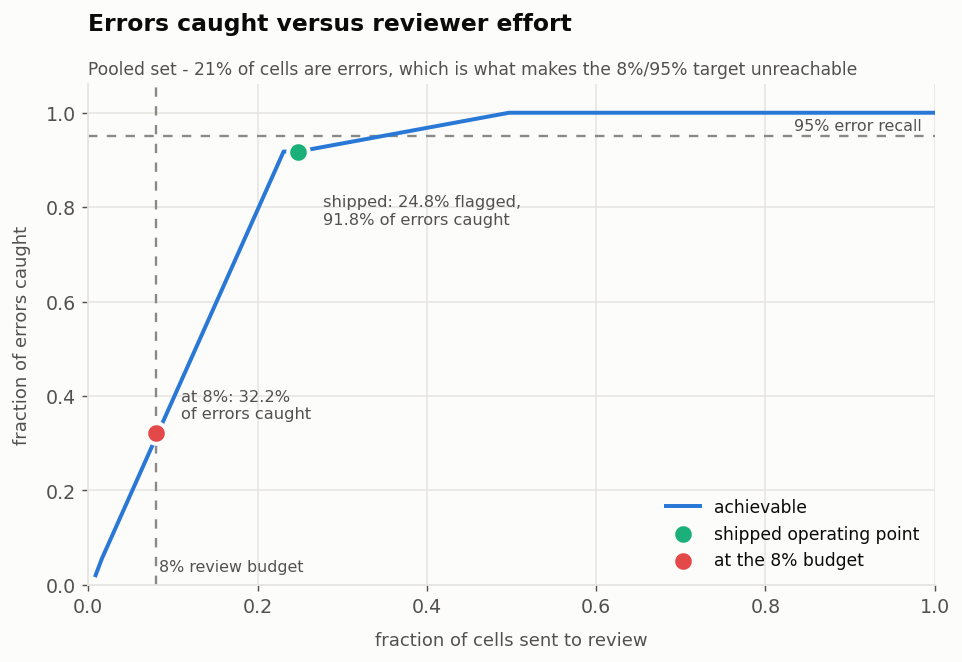

In [15]:
pr = calib["pr_curve"]
frac   = [p["flagged_frac"]  for p in pr]
recall = [p["error_recall"]  for p in pr]
op, bud = calib["operating_point"], calib["budget_point"]

fig, ax = plt.subplots(figsize=(8.4, 5.0))
ax.plot(frac, recall, linewidth=2.2, color=BLUE, zorder=3, label="achievable")

ax.axvline(0.08, color=INK_3, linestyle=(0, (4, 4)), linewidth=1.3, zorder=2)
ax.axhline(0.95, color=INK_3, linestyle=(0, (4, 4)), linewidth=1.3, zorder=2)
ax.text(0.084, 0.03, "8% review budget", fontsize=8.8, color=INK_2)
ax.text(0.985, 0.962, "95% error recall", fontsize=8.8, color=INK_2, ha="right")

ax.scatter([op["flagged_frac"]], [op["error_recall"]], s=130, color=GOOD,
           edgecolor=SURFACE, linewidth=2.2, zorder=5, label="shipped operating point")
ax.annotate(f'shipped: {op["flagged_frac"]*100:.1f}% flagged,\n'
            f'{op["error_recall"]*100:.1f}% of errors caught',
            (op["flagged_frac"], op["error_recall"]),
            textcoords="offset points", xytext=(14, -40), fontsize=9, color=INK_2)

ax.scatter([bud["budget_frac"]], [bud["error_recall"]], s=130, color=RED,
           edgecolor=SURFACE, linewidth=2.2, zorder=5, label="at the 8% budget")
ax.annotate(f'at 8%: {bud["error_recall"]*100:.1f}%\nof errors caught',
            (bud["budget_frac"], bud["error_recall"]),
            textcoords="offset points", xytext=(14, 8), fontsize=9, color=INK_2)

ax.set_xlim(0, 1.0); ax.set_ylim(0, 1.06)
ax.legend(loc="lower right")
finish(ax, "Errors caught versus reviewer effort",
       "Pooled set - 21% of cells are errors, which is what makes the 8%/95% target unreachable",
       xlabel="fraction of cells sent to review", ylabel="fraction of errors caught")
plt.show()

### On the 8% / 95% target, honestly

The brief sets a target of flagging ≤ 8% of cells while catching ≥ 95% of errors. On this
pooled set that is **arithmetically impossible**: 21% of the cells are errors, and you
cannot catch 95% of them by looking at 8% of the cells. At the 8% budget the curve
reaches 32.2% error recall, and that is the ceiling, not a tuning failure.

The target describes a regime where the error rate is well under 8%. In that regime — the
default configuration on real documents — the system flags 3–11% per document and has
**zero errors to catch**. The shipped operating point (mandatory reason codes, plus
confidence < 0.85) sits at 24.8% flagged / 91.8% caught, chosen deliberately: on a corpus
this error-dense, catching errors is worth more than a short queue.

**The number to hold this project to remains the silent-error count**, not this curve.

<a id="10"></a>
## 10. Resources

Against a budget of 20 minutes and 4 GB for a 100-page document.

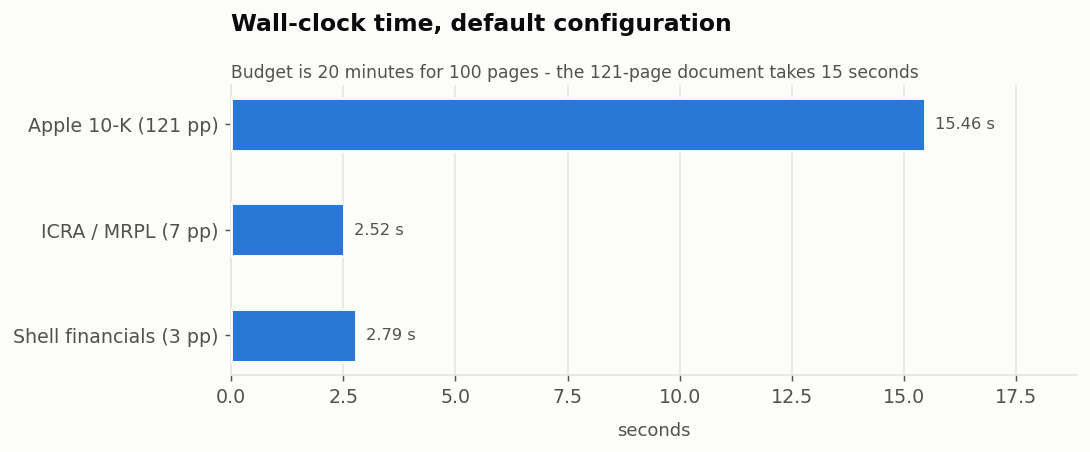

Apple 10-K: 15.5s over 121 pages = 0.128 s/page  ->  a 100-page document extrapolates to ~13s, against a 1200s budget.


In [16]:
res = all_configs["resources"]["default"]
name_of = {"apple": "Apple 10-K (121 pp)", "mrpl": "ICRA / MRPL (7 pp)",
           "shell": "Shell financials (3 pp)"}
keys = ["apple", "mrpl", "shell"]

fig, ax = plt.subplots(figsize=(8.4, 2.9))
vals = [res[k] for k in keys]
bars = ax.barh(np.arange(len(keys)), vals, 0.5, color=BLUE,
               edgecolor=SURFACE, linewidth=1.6, zorder=3)
for b, v in zip(bars, vals):
    ax.text(v + 0.22, b.get_y() + b.get_height() / 2, f"{v:.2f} s",
            va="center", fontsize=9, color=INK_2)
ax.set_yticks(np.arange(len(keys)))
ax.set_yticklabels([name_of[k] for k in keys])
ax.invert_yaxis(); ax.yaxis.grid(False)
ax.set_xlim(0, max(vals) * 1.22)
finish(ax, "Wall-clock time, default configuration",
       "Budget is 20 minutes for 100 pages - the 121-page document takes 15 seconds",
       xlabel="seconds")
plt.show()

print(f'Apple 10-K: {res["apple"]:.1f}s over 121 pages = '
      f'{res["apple"]/121:.3f} s/page  ->  a 100-page document extrapolates to '
      f'~{res["apple"]/121*100:.0f}s, against a 1200s budget.')

These timings are for runs **with no OCR**. A scanned 100-page document is unmeasured and
could plausibly approach the budget (LIMITATIONS L7).

---

<a id="11"></a>
## 11. Honest summary

**What the evidence actually supports.**

| Claim | Strength of evidence |
|---|---|
| Zero silent errors on the labelled set | **Strong** — but on documents that were tuned against |
| Refuses TOC/index/prose/callouts where baselines do not | **Strong** — 10/10 on `f4`, and the baselines' 6 FP each is independent corroboration |
| Handles cross-page tables, footnote links, scale, negatives, Indian grouping | **Strong** — fixtures, ground truth exact by construction, not tuned against |
| Confidence is calibrated | **Moderate** — ECE 0.029, but the negatives come from ablated runs, not from natural failures |
| Byte-reproducible output | **Strong** — mechanically verified, and asserted in CI on every push |
| Detection F1 = 1.000 | **Weak as a generalisation claim** — 10 tables on 3 developed-against documents |
| The borderless detector earns its place | **Absent** — `--no-borderless` costs nothing measurable here |
| The OCR path works | **Absent** — implemented, fails closed, has never read a real character |

**If I had more time, in order:** validate the OCR path against a real Tesseract install;
build the Docker image and fix whatever breaks; find or construct a corpus of genuinely
borderless tables to justify (or delete) the borderless detector; fix the `f1`
spanning-header cell; and recover the missing columns in the Shell cash-flow statement.

Full detail, with severities, is in [`docs/LIMITATIONS.md`](../docs/LIMITATIONS.md).